# Análise de vendas de videojogos

Projeto Integrado 1 — TripleTen. Análise académica para apoiar o planeamento de campanhas da loja fictícia Ice para 2017, com dados históricos até 2016.

As vendas representam milhões de unidades, não faturação ou lucro. O ano de 2016 pode conter dados incompletos.

In [4]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.stats import ttest_ind

df_principal = pd.read_csv('games.csv')

## Preparação de Dados

In [5]:
df_principal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [6]:
df_principal.head()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [7]:
df_principal.describe()

,Year_of_Release,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score
count,16446.000000,16715.000000,16715.000000,16715.000000,16715.000000,8137.000000
mean,2006.484616,0.263377,0.145060,0.077617,0.047342,68.967679
std,5.877050,0.813604,0.503339,0.308853,0.186731,13.938165
min,1980.000000,0.000000,0.000000,0.000000,0.000000,13.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,60.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,71.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,79.000000
max,2016.000000,41.360000,28.960000,10.220000,10.570000,98.000000


In [8]:
df_principal.isna().sum()

Name                  2
Platform              0
Year_of_Release     269
Genre                 2
NA_sales              0
EU_sales              0
JP_sales              0
Other_sales           0
Critic_Score       8578
User_Score         6701
Rating             6766
dtype: int64

In [9]:
df_principal.duplicated().sum()

0

In [10]:
df_principal.columns = df_principal.columns.str.lower()
print(df_principal.columns)

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='object')


In [11]:
anos_ausentes = df_principal[df_principal['year_of_release'].isna()].head()
print(anos_ausentes)

                           name platform  year_of_release     genre  na_sales  \
183             Madden NFL 2004      PS2              NaN    Sports      4.26   
377            FIFA Soccer 2004      PS2              NaN    Sports      0.59   
456  LEGO Batman: The Videogame      Wii              NaN    Action      1.80   
475  wwe Smackdown vs. Raw 2006      PS2              NaN  Fighting      1.57   
609              Space Invaders     2600              NaN   Shooter      2.36   

     eu_sales  jp_sales  other_sales  critic_score user_score rating  
183      0.26      0.01         0.71          94.0        8.5      E  
377      2.36      0.04         0.51          84.0        6.4      E  
456      0.97      0.00         0.29          74.0        7.9   E10+  
475      1.02      0.00         0.41           NaN        NaN    NaN  
609      0.14      0.00         0.03           NaN        NaN    NaN  


In [12]:
df_principal['year_of_release'] = df_principal['year_of_release'].astype('Int64')
print(df_principal['year_of_release'])

0        2006
1        1985
2        2008
3        2009
4        1996
         ... 
16710    2016
16711    2006
16712    2016
16713    2003
16714    2016
Name: year_of_release, Length: 16715, dtype: Int64


Comentário: 
Os valores ausentes da coluna 'year_of_release' foram mantidos como ausentes, pois não seria apropriado substituir por um valor qualquer como 0,, já que isso representaria um ano inexsistente, que poderia distorcer em uma análise futura. 

In [13]:
df_principal.info()
#só pra confirmar se tá tudo bem

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  Int64  
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       10014 non-null  object 
 10  rating           9949 non-null   object 
dtypes: Int64(1), float64(5), object(5)
memory usage: 1.4+ MB


In [14]:
#obj? TBD (to be determined) - 'user_score', 'rating'
verificar_user = df_principal['user_score'].value_counts(dropna=False)
print(verificar_user)

NaN    6701
tbd    2424
7.8     324
8       290
8.2     282
       ... 
0.9       2
0.7       2
1.3       2
0         1
9.7       1
Name: user_score, Length: 97, dtype: int64


In [15]:
verificar_rating = df_principal['rating'].value_counts(dropna=False)
print(verificar_rating)

NaN     6766
E       3990
T       2961
M       1563
E10+    1420
EC         8
K-A        3
RP         3
AO         1
Name: rating, dtype: int64


In [16]:
#rating é categorica, entao os valores NAN fazem sentido, caso não forem usados para nada ai sim mudamos
verificando_tbd = df_principal[df_principal['user_score'] == 'tbd'].head()
print(verificando_tbd)

                                         name platform  year_of_release  \
119                             Zumba Fitness      Wii             2010   
301            Namco Museum: 50th Anniversary      PS2             2005   
520                           Zumba Fitness 2      Wii             2011   
645                              uDraw Studio      Wii             2010   
657  Frogger's Adventures: Temple of the Frog      GBA             <NA>   

         genre  na_sales  eu_sales  jp_sales  other_sales  critic_score  \
119     Sports      3.45      2.59       0.0         0.66           NaN   
301       Misc      2.08      1.35       0.0         0.54          61.0   
520     Sports      1.51      1.03       0.0         0.27           NaN   
645       Misc      1.65      0.57       0.0         0.20          71.0   
657  Adventure      2.15      0.18       0.0         0.07          73.0   

    user_score rating  
119        tbd      E  
301        tbd   E10+  
520        tbd      T  
64

Comentário:
Os valores TBD presentes na coluna 'user_score' ela indica a pontuação dos usuários ainda não determinados. Portanto esses valores não foram considerados como 0 . Mas para permitir uma melhor análise numérica, esses valores serão convertidos para NAN que ainda preservará as pontuações que ainda não estão determinadas.

In [17]:
df_principal['user_score'] = df_principal['user_score'].replace('tbd', np.nan)
print(df_principal['user_score'])

0          8
1        NaN
2        8.3
3          8
4        NaN
        ... 
16710    NaN
16711    NaN
16712    NaN
16713    NaN
16714    NaN
Name: user_score, Length: 16715, dtype: object


In [18]:
df_principal['user_score'].value_counts(dropna = False).head()

NaN    9125
7.8     324
8       290
8.2     282
8.3     254
Name: user_score, dtype: int64

In [19]:
df_principal['user_score'] = pd.to_numeric(df_principal['user_score'])
print(df_principal['user_score'])

0        8.0
1        NaN
2        8.3
3        8.0
4        NaN
        ... 
16710    NaN
16711    NaN
16712    NaN
16713    NaN
16714    NaN
Name: user_score, Length: 16715, dtype: float64


Comentário: 
A coluna 'user_score' contém valores numéricos e valores ausentes, então tive que converter para um tipo numérico (float), pois como o conteúdo da coluna é de avaliação dos usuários não estava fazendo sentido ela estar como um tipo categório(object). Pois esses dados serão utilizados posteriormente em cálculos estatísticos, correlações e testes de hipótese. 

In [20]:
df_principal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  Int64  
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       7590 non-null   float64
 10  rating           9949 non-null   object 
dtypes: Int64(1), float64(6), object(4)
memory usage: 1.4+ MB


In [21]:
verificar_critic = df_principal['critic_score'].value_counts(dropna=False)
print(verificar_critic)

NaN     8578
70.0     256
71.0     254
75.0     245
78.0     240
        ... 
29.0       3
21.0       1
22.0       1
13.0       1
17.0       1
Name: critic_score, Length: 83, dtype: int64


In [22]:
investigando_critic = df_principal[df_principal['critic_score'].isna()].head()
print(investigando_critic)

                        name platform  year_of_release         genre  \
1          Super Mario Bros.      NES             1985      Platform   
4   Pokemon Red/Pokemon Blue       GB             1996  Role-Playing   
5                     Tetris       GB             1989        Puzzle   
9                  Duck Hunt      NES             1984       Shooter   
10                Nintendogs       DS             2005    Simulation   

    na_sales  eu_sales  jp_sales  other_sales  critic_score  user_score rating  
1      29.08      3.58      6.81         0.77           NaN         NaN    NaN  
4      11.27      8.89     10.22         1.00           NaN         NaN    NaN  
5      23.20      2.26      4.22         0.58           NaN         NaN    NaN  
9      26.93      0.63      0.28         0.47           NaN         NaN    NaN  
10      9.05     10.95      1.93         2.74           NaN         NaN    NaN  


In [23]:
verificando_rating = df_principal[df_principal['rating'].isna()].head()
print(verificando_rating)

                        name platform  year_of_release         genre  \
1          Super Mario Bros.      NES             1985      Platform   
4   Pokemon Red/Pokemon Blue       GB             1996  Role-Playing   
5                     Tetris       GB             1989        Puzzle   
9                  Duck Hunt      NES             1984       Shooter   
10                Nintendogs       DS             2005    Simulation   

    na_sales  eu_sales  jp_sales  other_sales  critic_score  user_score rating  
1      29.08      3.58      6.81         0.77           NaN         NaN    NaN  
4      11.27      8.89     10.22         1.00           NaN         NaN    NaN  
5      23.20      2.26      4.22         0.58           NaN         NaN    NaN  
9      26.93      0.63      0.28         0.47           NaN         NaN    NaN  
10      9.05     10.95      1.93         2.74           NaN         NaN    NaN  


In [24]:
#organizando vendas: totla_sales = na_sales + eu_sales + jp_sales +  other_sales
df_principal['total_sales'] = (
    df_principal['na_sales'] + 
    df_principal['eu_sales'] + 
    df_principal['jp_sales'] + 
    df_principal['other_sales']
)
print(df_principal['total_sales'])

0        82.54
1        40.24
2        35.52
3        32.77
4        31.38
         ...  
16710     0.01
16711     0.01
16712     0.01
16713     0.01
16714     0.01
Name: total_sales, Length: 16715, dtype: float64


In [25]:
#conferindo: 
df_principal[['name', 'na_sales', 'eu_sales', 'jp_sales', 'other_sales', 'total_sales' ]].head()

,name,na_sales,eu_sales,jp_sales,other_sales,total_sales
0,Wii Sports,41.36,28.96,3.77,8.45,82.54
1,Super Mario Bros.,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,15.68,12.76,3.79,3.29,35.52
3,Wii Sports Resort,15.61,10.93,3.28,2.95,32.77
4,Pokemon Red/Pokemon Blue,11.27,8.89,10.22,1.00,31.38


In [26]:
df_principal['total_sales'].describe()

count    16715.000000
mean         0.533396
std          1.548261
min          0.000000
25%          0.060000
50%          0.170000
75%          0.470000
max         82.540000
Name: total_sales, dtype: float64

In [27]:
df_principal['total_sales'].isna().sum()

0

In [28]:
#conferindo se tá tudo salvo e tudo bem: 
df_principal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  Int64  
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       7590 non-null   float64
 10  rating           9949 non-null   object 
 11  total_sales      16715 non-null  float64
dtypes: Int64(1), float64(7), object(4)
memory usage: 1.5+ MB


## Conclusão da Preparação de Dados: 

Durante a preparação dos dados, os nomes das colunas foram convertidos para letras minusculas para padronizar o conjunto de dados e facilitar a manipulação. 

Coluna 'year_of_release': foi convertida de 'float' para 'Int64', pois a coluna representa anos que são números inteiros. O uso do 'Int64' foi para manter os valores ausentes sem substitui-los por informações que poderiam mudar o resultado de análises futuras.

Coluna 'user_score': os valores 'TBD' foram substituidos por valores 'NaN', pois indicam que a pontuação dos usuários não estava determinada, não podia ser substituida por 0 pois alteraria resultados de análise no futuro. A coluna foi convertida para tipo numério ('float64') que permite a realização de cálculos estatíticos. 

Coluna 'critic_score': já estava no formato númerico e os valores ausentes foram preservados, pois não havia informações suficientes para determinar as pontuações que estavam faltando. 

Coluna 'rating': foi mantida como tipo 'object', pois representa classificações do ESRB e não valores numéricos. Os valores ausentes também foram mantidos por conta que não seria adequado atribuir uma classificação sem informação disponível.

As colunas de vendas já estavam em formato correto e foram utilizadas para criar a coluna 'total_sales' que representa a soma das vendas de cada jogo na América do Norte, Europa, Japão e outras regiões.

## Analise de Dados

In [29]:
jogos_por_ano = df_principal.groupby('year_of_release')['name'].count().reset_index(name = 'game_count')
print(jogos_por_ano)

    year_of_release  game_count
0              1980           9
1              1981          46
2              1982          36
3              1983          17
4              1984          14
5              1985          14
6              1986          21
7              1987          16
8              1988          15
9              1989          17
10             1990          16
11             1991          41
12             1992          43
13             1993          60
14             1994         121
15             1995         219
16             1996         263
17             1997         289
18             1998         379
19             1999         338
20             2000         350
21             2001         482
22             2002         829
23             2003         775
24             2004         762
25             2005         939
26             2006        1006
27             2007        1197
28             2008        1427
29             2009        1426
30      

In [30]:
vendas_por_plataforma = (
    df_principal.groupby('platform')
    ['total_sales'].sum().sort_values(ascending=False)
)
print(vendas_por_plataforma)

platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
PS       730.86
GBA      317.85
PS4      314.14
PSP      294.05
PC       259.52
3DS      259.00
XB       257.74
GB       255.46
NES      251.05
N64      218.68
SNES     200.04
GC       198.93
XOne     159.32
2600      96.98
WiiU      82.19
PSV       54.07
SAT       33.59
GEN       30.77
DC        15.95
SCD        1.86
NG         1.44
WS         1.42
TG16       0.16
3DO        0.10
GG         0.04
PCFX       0.03
Name: total_sales, dtype: float64


In [31]:
#vendas cada plataforma teve em cada ano: 
vendas_por_plataforma_ano = (
    df_principal.groupby(['year_of_release','platform'])['total_sales'].sum()
    .reset_index()
)
print(vendas_por_plataforma_ano)

     year_of_release platform  total_sales
0               1980     2600        11.38
1               1981     2600        35.68
2               1982     2600        28.88
3               1983     2600         5.84
4               1983      NES        10.96
..               ...      ...          ...
233             2016      PSV         4.25
234             2016      Wii         0.18
235             2016     WiiU         4.60
236             2016     X360         1.52
237             2016     XOne        26.15

[238 rows x 3 columns]


In [32]:
#investigando: vendas_por_plataforma_ano
vendas_recentes = vendas_por_plataforma_ano[
    (vendas_por_plataforma_ano['year_of_release'] == 2015) |
    (vendas_por_plataforma_ano['year_of_release'] == 2016)
    ]
vendas_recentes = vendas_recentes.sort_values(['year_of_release','total_sales'], ascending=False)
print(vendas_recentes)

     year_of_release platform  total_sales
232             2016      PS4        69.25
237             2016     XOne        26.15
229             2016      3DS        15.14
230             2016       PC         5.25
235             2016     WiiU         4.60
233             2016      PSV         4.25
231             2016      PS3         3.60
236             2016     X360         1.52
234             2016      Wii         0.18
222             2015      PS4       118.90
228             2015     XOne        60.14
219             2015      3DS        27.78
221             2015      PS3        16.82
226             2015     WiiU        16.35
227             2015     X360        11.96
220             2015       PC         8.52
224             2015      PSV         6.25
225             2015      Wii         1.14
223             2015      PSP         0.12


In [33]:
plataformas_escolhidas = ['PS4','XOne','3DS','X360','PC']

vendas_5_plataformas = vendas_recentes[
    vendas_recentes['platform'].isin(plataformas_escolhidas)
    ]
print(vendas_5_plataformas)

     year_of_release platform  total_sales
232             2016      PS4        69.25
237             2016     XOne        26.15
229             2016      3DS        15.14
230             2016       PC         5.25
236             2016     X360         1.52
222             2015      PS4       118.90
228             2015     XOne        60.14
219             2015      3DS        27.78
227             2015     X360        11.96
220             2015       PC         8.52


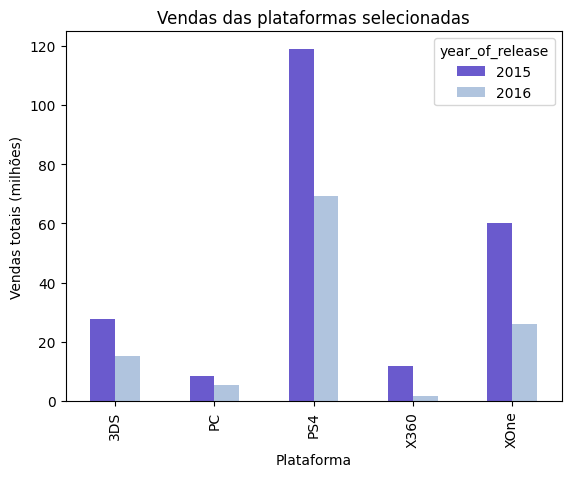

In [34]:
grafico_vendas = vendas_5_plataformas.pivot(
    index = 'platform',
    columns = 'year_of_release',
    values = 'total_sales'
)
grafico_vendas.plot(kind= 'bar',
                   title= 'Vendas das plataformas selecionadas',
                   xlabel= 'Plataforma',
                   ylabel= 'Vendas totais (milhões)',
                    color= ['slateblue','lightsteelblue']
                   )
plt.show()

In [35]:
#quais anos cada plataforma apareceu e em quais anos deixou de aparecer
linhadetempo_plataformas = (
    df_principal.groupby('platform')['year_of_release']
        .agg(['min','max'])
        .sort_values('min')
)
print(linhadetempo_plataformas)

           min   max
platform            
2600      1980  1989
NES       1983  1994
DS        1985  2013
PC        1985  2016
GB        1988  2001
SNES      1990  1999
GEN       1990  1994
GG        1992  1992
SCD       1993  1994
NG        1993  1996
SAT       1994  1999
PS        1994  2003
3DO       1994  1995
TG16      1995  1995
PCFX      1996  1996
N64       1996  2002
DC        1998  2008
WS        1999  2001
GBA       2000  2007
XB        2000  2008
PS2       2000  2011
GC        2001  2007
PSP       2004  2015
X360      2005  2016
PS3       2006  2016
Wii       2006  2016
3DS       2011  2016
PSV       2011  2016
WiiU      2012  2016
PS4       2013  2016
XOne      2013  2016


In [36]:
#quanto tempo leva para as novas plataformas aparecerem e as antigas desaparecerem 
linhadetempo_plataformas['duration'] = (
    linhadetempo_plataformas['max'] - linhadetempo_plataformas['min'] + 1
)
linhadetempo_plataformas = linhadetempo_plataformas.sort_values('duration', ascending=True)

print(linhadetempo_plataformas)

           min   max  duration
platform                      
GG        1992  1992         1
TG16      1995  1995         1
PCFX      1996  1996         1
SCD       1993  1994         2
3DO       1994  1995         2
WS        1999  2001         3
XOne      2013  2016         4
NG        1993  1996         4
PS4       2013  2016         4
WiiU      2012  2016         5
GEN       1990  1994         5
PSV       2011  2016         6
3DS       2011  2016         6
SAT       1994  1999         6
GC        2001  2007         7
N64       1996  2002         7
GBA       2000  2007         8
XB        2000  2008         9
SNES      1990  1999        10
PS        1994  2003        10
2600      1980  1989        10
DC        1998  2008        11
PS3       2006  2016        11
Wii       2006  2016        11
PS2       2000  2011        12
PSP       2004  2015        12
X360      2005  2016        12
NES       1983  1994        12
GB        1988  2001        14
DS        1985  2013        29
PC      

Comentário: 
Na análise da linha de tempo das plataformas mostra que o mercado de videogames passou por uma renovação constante,enquanto novas plataformas acabavam surgindo outras deixavam de apresentar registros de vendas. Entre as plataformas analisadas, algumas permaneceram por períodos mais longos, como o PC com 32 anos e o DS com 29 anos. Dessa forma, podemos observar que o ciclo das plataformas varia bastate e a duração que foi calculada representa o intervalo de tempo entre o primeiro e último ano que houve registro no dataset, não necessariamente o tempo real de permanência da plataforma no mercado. 

In [37]:
vendas_por_ano = vendas_por_plataforma_ano.groupby('year_of_release')['total_sales'].sum()
print(vendas_por_ano)

year_of_release
1980     11.38
1981     35.68
1982     28.88
1983     16.80
1984     50.35
1985     53.95
1986     37.08
1987     21.70
1988     47.21
1989     73.45
1990     49.37
1991     32.23
1992     76.16
1993     48.41
1994     79.23
1995     88.12
1996    199.15
1997    201.07
1998    256.31
1999    251.11
2000    201.66
2001    331.46
2002    394.97
2003    357.54
2004    418.68
2005    457.82
2006    517.71
2007    604.75
2008    671.50
2009    658.82
2010    590.13
2011    507.58
2012    355.84
2013    361.24
2014    331.53
2015    267.98
2016    129.94
Name: total_sales, dtype: float64


Comentário: 
Com base nas análises anteriores, selecionamos o período de 2013 á 2016 por ser o intervalo mais recente disponível no dataset. Esses anos representam o melhor cenário para o próximo ano de 2017, que nos permite observar a evolução da plataforma e da geração mais recente, que evita dados mais antigos que podem influenciar para uma análise errada. 

In [38]:
# 2013 á 2016
df_relevante = df_principal[
    (df_principal['year_of_release'] >= 2013) &
    (df_principal['year_of_release'] <= 2016)
].copy()
print(df_relevante['year_of_release'].value_counts().sort_index())

2013    544
2014    581
2015    606
2016    502
Name: year_of_release, dtype: Int64


In [39]:
#df_relevante é só de 2013 á 2016
vendas_relevantes_por_plataforma = df_relevante.groupby('platform')['total_sales'].sum()
print(vendas_relevantes_por_plataforma)

platform
3DS     143.25
DS        1.54
PC       39.43
PS3     181.43
PS4     314.14
PSP       3.50
PSV      32.99
Wii      13.66
WiiU     64.63
X360    136.80
XOne    159.32
Name: total_sales, dtype: float64


In [40]:
vendas_relevantes_por_ano = df_relevante.groupby(
    ['platform','year_of_release' ]
)['total_sales'].sum()
print(vendas_relevantes_por_ano)

platform  year_of_release
3DS       2013                56.57
          2014                43.76
          2015                27.78
          2016                15.14
DS        2013                 1.54
PC        2013                12.38
          2014                13.28
          2015                 8.52
          2016                 5.25
PS3       2013               113.25
          2014                47.76
          2015                16.82
          2016                 3.60
PS4       2013                25.99
          2014               100.00
          2015               118.90
          2016                69.25
PSP       2013                 3.14
          2014                 0.24
          2015                 0.12
PSV       2013                10.59
          2014                11.90
          2015                 6.25
          2016                 4.25
Wii       2013                 8.59
          2014                 3.75
          2015                 1.14
  

plataformas escolhidas: PS4 , XOne , 3DS 
PS4 e XOne representam plataformas com forte crescimento e grande volume de vendas, enquanto o 3DS apesar da tendência de queda, ainda mantém um volume relevante de vendas e pode continuar sendo uma plataforma importante para 2017. 

In [41]:

vendas_medias_plataforma = df_relevante.groupby('platform')['total_sales'].mean()
print(vendas_medias_plataforma.sort_values(ascending=False))


platform
PS4     0.801378
X360    0.735484
XOne    0.645020
Wii     0.593913
WiiU    0.562000
PS3     0.525884
3DS     0.472772
PC      0.208624
DS      0.192500
PSV     0.092151
PSP     0.052239
Name: total_sales, dtype: float64


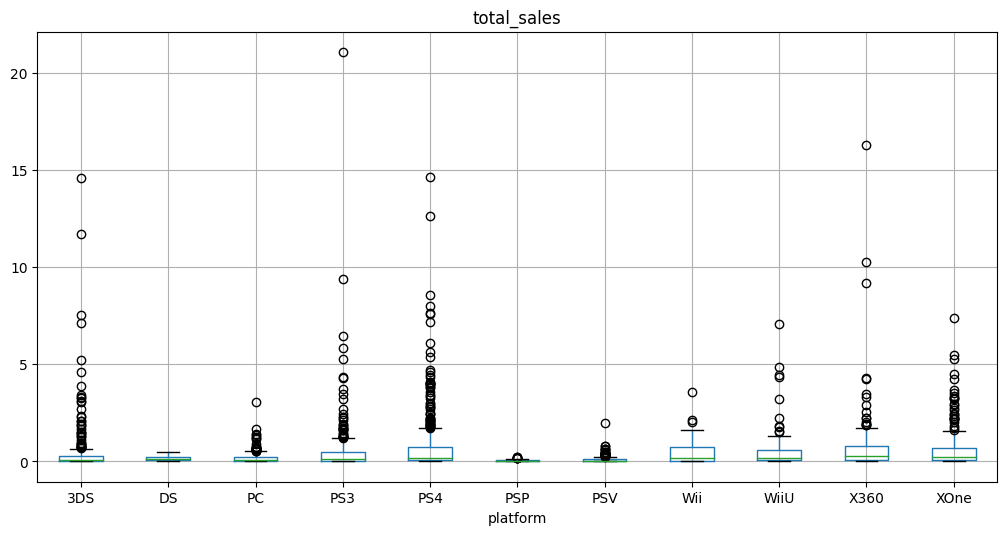

In [42]:

#construção do diagrama
df_relevante.boxplot(
    column= 'total_sales',
    by= 'platform',
    figsize= (12,6)
)

plt.suptitle('')
plt.show()


Comentário:
PS4, XOne, 3DS, X360 e PC. PS4 e XOne apresentam um bom volume de vendas e tiveram bastante relevância nos últimos anos. O 3DS apesar de apresentar uma tendência de queda, ainda possui um volume relevante de vendas. O X360 foi escolhido por apresentar vendas significativas no período analisado, enquanto o PC foi incluído por ter uma presença mais longa no mercado.

In [43]:
#ps4
dados_ps4 = df_relevante[df_relevante['platform']== 'PS4']
print(dados_ps4.head())

                              name platform  year_of_release    genre  \
31       Call of Duty: Black Ops 3      PS4             2015  Shooter   
42              Grand Theft Auto V      PS4             2014   Action   
77                         FIFA 16      PS4             2015   Sports   
87    Star Wars Battlefront (2015)      PS4             2015  Shooter   
92  Call of Duty: Advanced Warfare      PS4             2014  Shooter   

    na_sales  eu_sales  jp_sales  other_sales  critic_score  user_score  \
31      6.03      5.86      0.36         2.38           NaN         NaN   
42      3.96      6.31      0.38         1.97          97.0         8.3   
77      1.12      6.12      0.06         1.28          82.0         4.3   
87      2.99      3.49      0.22         1.28           NaN         NaN   
92      2.81      3.48      0.14         1.23          83.0         5.7   

   rating  total_sales  
31    NaN        14.63  
42      M        12.62  
77      E         8.58  
87    NaN 

In [44]:
ps4_critic = dados_ps4[dados_ps4['critic_score'].notna()]
print(ps4_critic)

                                        name platform  year_of_release  \
42                        Grand Theft Auto V      PS4             2014   
77                                   FIFA 16      PS4             2015   
92            Call of Duty: Advanced Warfare      PS4             2014   
94                                   FIFA 17      PS4             2016   
105                                Fallout 4      PS4             2015   
...                                      ...      ...              ...   
16486                     Super Dungeon Bros      PS4             2016   
16499  Sherlock Holmes: The Devil's Daughter      PS4             2016   
16500                            Root Letter      PS4             2016   
16526                             Dungeons 2      PS4             2016   
16530                Carmageddon: Max Damage      PS4             2016   

              genre  na_sales  eu_sales  jp_sales  other_sales  critic_score  \
42           Action      3.96  

In [45]:
ps4_user = dados_ps4[dados_ps4['user_score'].notna()]
print(ps4_user.shape)

(257, 12)


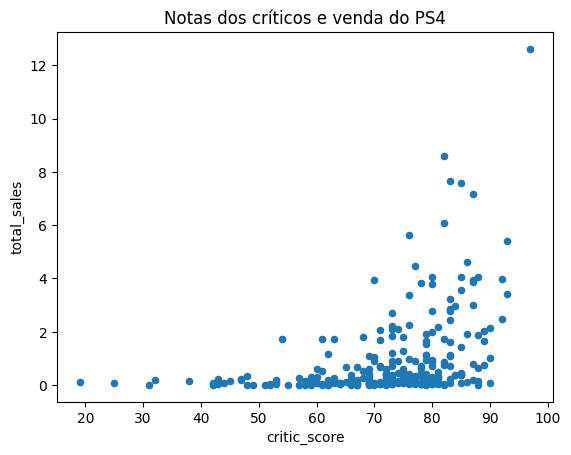

In [46]:
ps4_critic.plot(
    kind= 'scatter', 
    x= 'critic_score',
    y= 'total_sales',
    title= 'Notas dos críticos e venda do PS4'
)
plt.show()

In [47]:
#calculando coerelação: 
correlacao_ps4_critic = ps4_critic['critic_score'].corr(ps4_critic['total_sales'])
print(correlacao_ps4_critic)

0.40656790206178095


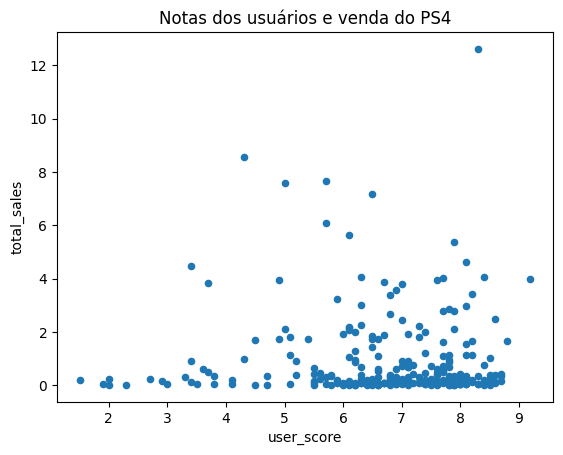

In [67]:
ps4_user.plot(
    kind= 'scatter', 
    x= 'user_score',
    y= 'total_sales',
    title= 'Notas dos usuários e venda do PS4'
)
plt.show()

In [49]:
correlacao_ps4_user = ps4_user['user_score'].corr(ps4_user['total_sales'])
print(correlacao_ps4_user)

-0.031957110204556376


Comentário:
No PS4, as avaliações dos críticos apresentam uma correlação positiva moderada com as vendas (aproximadamente: 0.41), enquanto as avaliações dos usuários apresentam uma correlação praticamente nula (aproximadamente: - 0.03). Isso sugere que nesse conjunto de dados, as avaliações dos profissionais estão mais associadas as vendas do que as avaliações dos usuários. 

In [50]:
#usar merge que dá pegar os nomes que tão no dados_ps4 e juntar com as outras plataformas
jogos_ps4_outras = dados_ps4[['name']].merge(
    df_relevante[['name','platform','total_sales']],
    on= 'name'
)
print(jogos_ps4_outras)

                               name platform  total_sales
0         Call of Duty: Black Ops 3      PS4        14.63
1         Call of Duty: Black Ops 3     XOne         7.39
2         Call of Duty: Black Ops 3     X360         1.70
3         Call of Duty: Black Ops 3      PS3         1.69
4         Call of Duty: Black Ops 3       PC         0.26
...                             ...      ...          ...
1123              Shin Hayarigami 2      PS4         0.01
1124                     Dungeons 2      PS4         0.01
1125        Carmageddon: Max Damage     XOne         0.02
1126        Carmageddon: Max Damage      PS4         0.01
1127  Farming 2017 - The Simulation      PS4         0.01

[1128 rows x 3 columns]


In [51]:
vendas_medias_outras = jogos_ps4_outras.groupby('platform')['total_sales'].mean()
print(vendas_medias_outras)

platform
3DS     0.289474
DS      0.380000
PC      0.214476
PS3     0.771818
PS4     0.801378
PSP     0.120000
PSV     0.144512
Wii     1.117000
WiiU    0.329143
X360    1.072900
XOne    0.596129
Name: total_sales, dtype: float64


In [52]:
df_relevante['genre'].value_counts()

Action          766
Role-Playing    292
Adventure       245
Sports          214
Shooter         187
Misc            155
Racing           85
Fighting         80
Platform         74
Simulation       62
Strategy         56
Puzzle           17
Name: genre, dtype: int64

In [53]:
vendas_por_genero = df_relevante.groupby('genre')['total_sales'].median()
print(vendas_por_genero)

genre
Action          0.110
Adventure       0.030
Fighting        0.125
Misc            0.100
Platform        0.225
Puzzle          0.060
Racing          0.120
Role-Playing    0.125
Shooter         0.450
Simulation      0.100
Sports          0.240
Strategy        0.080
Name: total_sales, dtype: float64


In [54]:
vendas_por_genero = df_relevante.groupby('genre')['total_sales'].mean()
print(vendas_por_genero)

genre
Action          0.420196
Adventure       0.096490
Fighting        0.441375
Misc            0.405290
Platform        0.576081
Puzzle          0.186471
Racing          0.469294
Role-Playing    0.499623
Shooter         1.245882
Simulation      0.350968
Sports          0.703972
Strategy        0.180000
Name: total_sales, dtype: float64


Comentário:
A quantidade de jogos de um género não determina sua desempenho em vendas. Embora o género 'Action' seja o género mais frequênte no período foi analisado,o jogo com o género 'Shooter'apresentam as maiores vendas médias e medianas. Já géneros como 'Adventure','Strategy'e'Puzzle' apresentam vendas significativamente menores. Isso indica que a popularidade de um género em quantidade de lançamentos não necessariamente corresponde ao seu desempenho comercial. 

## Conclusão da Análise de Dados:

A análise dos dados permitiu identificar o período mais relevante para representar o cenário mais recente do mercado, considerando os anos de 2013 a 2016. Observamos que o tempo de permanência de uma platforma no mercado não determina, por si só, sua competitividade ou desempenho comercial, já que diferentes plataformas apresentam comportamentos distintos ao longo do período. 

Também indentificamos diferenças importantes entre plataforma e géneros, permitindo reconhecer padrões de vendas e possíveis oportunidades que poderão ser exploradas nas próximas etapas da análise.

## Análise Regional

In [55]:
#encontrar o Top 5 plataformas principais de (AN, UE e JP)
top5_an = df_relevante.groupby('platform')['na_sales'].sum().sort_values(ascending=False).head(5)
print(top5_an)

top5_ue = df_relevante.groupby('platform')['eu_sales'].sum().sort_values(ascending=False).head(5)
print(top5_ue)

top5_jp = df_relevante.groupby('platform')['jp_sales'].sum().sort_values(ascending=False).head(5)
print(top5_jp)

platform
PS4     108.74
XOne     93.12
X360     81.66
PS3      63.50
3DS      38.20
Name: na_sales, dtype: float64
platform
PS4     141.09
PS3      67.81
XOne     51.59
X360     42.52
3DS      30.96
Name: eu_sales, dtype: float64
platform
3DS     67.81
PS3     23.35
PSV     18.59
PS4     15.96
WiiU    10.88
Name: jp_sales, dtype: float64


In [56]:
vendas_regionais = df_relevante[['na_sales', 'eu_sales', 'jp_sales']].sum()
print(vendas_regionais)

na_sales    437.71
eu_sales    392.23
jp_sales    140.78
dtype: float64


In [68]:

#variações das suas quotas de mercado de região para região.
#top5_AN = df_relevante.groupby('platform')['na_sales'].sum().sort_values(ascending=False).head(5)
quota_an = (top5_an / vendas_regionais['na_sales'])*100
print(quota_an)

#top5_UE = df_relevante.groupby('platform')['ue_sales'].sum().sort_values(ascending=False).head(5)
quota_ue = (top5_ue / vendas_regionais['eu_sales'])*100
print(quota_ue)

#top5_JP = df_relevante.groupby('platform')['jp_sales'].sum().sort_values(ascending=False).head(5)
quota_jp = (top5_jp / vendas_regionais['jp_sales'])*100
print(quota_jp)


platform
PS4     24.842933
XOne    21.274360
X360    18.656188
PS3     14.507322
3DS      8.727239
Name: na_sales, dtype: float64
platform
PS4     35.971241
PS3     17.288326
XOne    13.152997
X360    10.840578
3DS      7.893328
Name: eu_sales, dtype: float64
platform
3DS     48.167353
PS3     16.586163
PSV     13.205001
PS4     11.336838
WiiU     7.728371
Name: jp_sales, dtype: float64


Comentário:
AN e UE apresentam uma distribuição de mercado relativamente semelhantes, como o PS4 como principal e com uma forte participação das plataformas Xbox e PlayStation. Porém na Europa o PS4 apresenta uma participação ainda maior, chegando a 35.97% das vendas. Já o Japão apresenta uma distribuição diferente, marcada pelo forte domínio do 3DS e pela presença de plataformas que não aparecem entre as cinco principais de AN e UE.
Não é apenas que as plataformas não vendem quantidades diferentes em cada região, a própria composição de mercado muda.

In [58]:
#top 5 géneros
top5_genre_an = df_relevante.groupby('genre')['na_sales'].sum().sort_values(ascending=False).head(5)
print(top5_genre_an)

top5_genre_ue = df_relevante.groupby('genre')['eu_sales'].sum().sort_values(ascending=False).head(5)
print(top5_genre_ue)

top5_genre_jp = df_relevante.groupby('genre')['jp_sales'].sum().sort_values(ascending=False).head(5)
print(top5_genre_jp)

genre
Action          126.05
Shooter         109.74
Sports           65.27
Role-Playing     46.40
Misc             27.49
Name: na_sales, dtype: float64
genre
Action          118.13
Shooter          87.86
Sports           60.52
Role-Playing     36.97
Racing           20.19
Name: eu_sales, dtype: float64
genre
Role-Playing    51.04
Action          40.49
Misc             9.20
Fighting         7.65
Shooter          6.61
Name: jp_sales, dtype: float64


Comentário:
AN e UE apresentam padrões de consumo semelhantes com géneros: 'Action', 'Shooter','Sports' e 'Role-Playing' dominando as vendas. O Japão podemos observar que apresenta uma distribuição diferente com o género: 'Role-Playing' liberando e 'Fighting' ganhando maior relevância, enquanto 'Shooter' possui uma participação menor. Isso indica que a preferência por géneros varia significativamente entre as regiões analisadas.

In [59]:
#ESRB:
df_relevante['rating'].value_counts()

M       369
T       333
E       302
E10+    252
Name: rating, dtype: int64

In [60]:
vendas_esrb_an = df_relevante.groupby('rating')['na_sales'].mean()
print(vendas_esrb_an)

vendas_esrb_ue = df_relevante.groupby('rating')['eu_sales'].mean()
print(vendas_esrb_ue)

vendas_esrb_jp = df_relevante.groupby('rating')['jp_sales'].mean()
print(vendas_esrb_jp)

rating
E       0.261755
E10+    0.215238
M       0.447724
T       0.149520
Name: na_sales, dtype: float64
rating
E       0.276026
E10+    0.169405
M       0.393821
T       0.125976
Name: eu_sales, dtype: float64
rating
E       0.050132
E10+    0.023373
M       0.038238
T       0.061832
Name: jp_sales, dtype: float64


Comentário: As vendas médias variam de acordo com a classificação ESRB e esse comportamento também varia entre as regiões. Na AN e UE, os jogos classificados como M (AN: 0.44 & UE: 0.39) apresentam as maiores médias de vendas, enquanto no Japão a classificação T (0.06) apresentou a maior média. Isso indica que existe uma relação entre as classificações e o desempenho de vendas, mas o efeito não é igual em todas as regiões.

## Conclusão da Análise Regional

A análise regional mostrou que o comportamento do mercado varia entre as regiões. AN e UE apresentam padrões semelhantes nas platafromas e géneros mais vendidos. Enquanto o Japão apresentou preferências distintas. As classificações ESRB também apresentam difrenças nas vendas médias entre as regiões, reforçando que o mercado de videogames possui características específicas de acordo com cada região. 

## Análise Estatística

In [61]:
#As médias dos usuários XOne e PC são as mesmas: 

#H₀: as classificações médias dos usuários de Xbox One e PC são iguais.
#H₁: as classificações médias dos usuários de Xbox One e PC são diferentes.

#α = 0,05

notas_xone = df_relevante[df_relevante['platform']== 'XOne']['user_score'].dropna()
notas_pc = df_relevante[df_relevante['platform']== 'PC']['user_score'].dropna()

print(len(notas_xone))
print(len(notas_pc))

182
155


In [62]:
print('Média XOne:', notas_xone.mean())
print('Média PC:', notas_pc.mean())

Média XOne: 6.521428571428572
Média PC: 6.2696774193548395


In [63]:
resultado_xone_pc = ttest_ind(
    notas_xone,
    notas_pc,
    equal_var=False
)
print(resultado_xone_pc)

Ttest_indResult(statistic=1.45192815744488, pvalue=0.14759594013430463)


### Teste de Hipótese - Xbox One e PC: 
Para comparar as classificações médias dos usuários das plataformas Xbox One e PC, foram formuladas as seguintes hipóteses:

H₀: as médias das classificações dos usuários de Xbox One e PC são iguais.

H₁: as médias das classificações dos usuários de Xbox One e PC são diferentes.

Foi utilizado um nível de signficância de α = 0,05. O teste apresentou p-value de aproximadamente 0.147, superior ao nível de significância escolhida. Portanto não rejeitamos a hipótese nula. Apesar da média do Xbox One (6.52) ser ligeiramente superior a do PC (6.27), não foi encontrado evidências estatísticas suficientes para afirmar que existe uma diferença significativa entre as médias.

In [64]:
# médias de usuários para os generos Action e Sports são diferentes:

#H₀: as médias das classificações dos usuários de Action e Sports são iguais.
#H₁: as médias das classificações dos usuários de Action e Sports são diferentes.

#α = 0,05

notas_action = df_relevante[df_relevante['genre'] == 'Action']['user_score'].dropna()
notas_sports = df_relevante[df_relevante['genre'] == 'Sports']['user_score'].dropna()

print(len(notas_action))
print(len(notas_sports))

389
160


In [65]:
print('Média Action:', notas_action.mean())
print('Média Sports:', notas_sports.mean())

Média Action: 6.837532133676092
Média Sports: 5.238124999999999


In [66]:
resultados_action_sports = ttest_ind(
    notas_action,
    notas_sports, 
    equal_var=False
)
print(resultados_action_sports)

Ttest_indResult(statistic=10.233428417448625, pvalue=1.4460039700704315e-20)


### Teste de Hipótese - Action e Sports: 

Para comparar as classificações médias dos usuários dos géneros Action e Sports, foram formuladas as seguintes hipóteses: 

H₀: as médias das classificações dos usuários de Action e Sports são iguais.

H₁: as médias das classificações dos usuários de Action e Sports são diferentes.

Foi utilizado um nível de significância de α = 0,05. O teste apresentou um p-value aproximadamente igual a 1.45 * 10⁻²⁰, inferior ao nível de significância escolhido. Portanto rejeitamos a hipótese nula e concluímos que exitem evidências estatísticas de que as médias das classificações dos usuários dos dois géneros são diferentes. Na amostra analisada, Action apresentou média de 6.83 e Sports apresentou média de 5.23.

## Conclusão da Análise Estatística
Nessa etapa, foram realizados testes de hipóteses para comparar as classificações médias dos usuários. Foi adotado um nível de significância de 0.05, é um valor convencional que permite controlar em 5% o risco de rejeitar a hipótese nula quando ela é verdadeira, tornando a análise mais criteriosa.
Os resultados mostraram que não houve evidência suficientes para afirmar uma diferença significativa entre as médias de Xbox One e PC. Já entre os géneros: Action e Sports, foi identificada um diferença estatisticamente significativa nas classificações médias dos usuários. 

## Conclusão Geral do Projeto:

O protejo teve como objetivo principal analisar o mercado de videogames, para identificar oportunidades que pudessem apoiar as decisões da loja online Ice para o ano de 2017. Após a preparação de dados e a análise da evolução das plataformas, concentramos a análise no período dos anos 2013 a 2016, por representar um cenário mais recente e relevante para avaliar o comportamento do mercado. 

A análise mostrou que o desempenho dos videogames varia de acordo com a plataforma, género e a região. América do Norte (AN) e Europa (UE) apresentam padrões relativamente semelhantes com a plataforma 'PS4' apresentando forte desempenho, podendo representar uma oportunidade para campanhas direcionadas a essa plataforma e região. Enquanto o Japão (JP) apresenta características distantas, com destaque para a plataforma '3DS' e para o género 'Role-Playing', o que indica uma oportunidade de campanha diferente. 
As diferenças entre géneros mais vendidos também reforçam a importância de adaptar as estratégias às caractéristicas de cada mercado. 

Os testes estatísticos complementaram a análise ao mostrar que algumas diferenças entre as avaliações dos usuários são estatisticamente significativas, enquanto outras não apresentam evidências suficientes. 

Dessa forma, os resultados obtidos podem ajudar a loja Ice a identificar possíveis oportunidade de mercado e planear campanhas publicitárias mais direcionadas no ano de 2017, utilizando o histórico de vendas e as caracteríticas de cada região como apoio às decisões.